# 🚗 Emergi-Sensei: Two-Stage Hierarchical Vehicle & Accident Detection Pipeline

This notebook demonstrates the end-to-end architecture:
- **Stage 1 (Vehicle Pre-Detection)**: Uses a Hugging Face vision model (`google/mobilenet_v2_1.0_224` & SSDLite COCO detector) to verify if a car/vehicle is present in the frame.
- **Stage 2 (Accident Risk Inference)**: If a vehicle is detected, calculates the accident probability using a fine-tuned MobileNetV2 classifier (`accident_model.keras`). If no vehicle is present, immediately classifies as 'Safe (No Vehicle)', preventing false positives.

## 1. Environment Setup & Data Loading


In [1]:
import os
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image
import torch
from transformers import AutoImageProcessor, AutoModelForImageClassification
import tensorflow as tf
from tensorflow.keras import layers, models, regularizers

IMG_SIZE = (224, 224)
BATCH_SIZE = 32

print('TensorFlow version:', tf.__version__)
print('PyTorch version:', torch.__version__)

# Load training, validation, and test datasets
if os.path.exists('merged_dataset'):
    train_ds = tf.keras.preprocessing.image_dataset_from_directory(
        'merged_dataset/train', image_size=IMG_SIZE, batch_size=BATCH_SIZE)
    val_ds = tf.keras.preprocessing.image_dataset_from_directory(
        'merged_dataset/val', image_size=IMG_SIZE, batch_size=BATCH_SIZE)
    test_ds = tf.keras.preprocessing.image_dataset_from_directory(
        'merged_dataset/test', image_size=IMG_SIZE, batch_size=BATCH_SIZE, shuffle=False)
    print('Datasets loaded successfully!')
else:
    print('merged_dataset folder not found in current directory.')


Could not save font_manager cache [Errno 13] Permission denied: 'C:\\Users\\ABHIROOP\\.matplotlib\\fontlist-v390.json.matplotlib-lock'
c:\Users\ABHIROOP\anaconda3\envs\chatbot\lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
c:\Users\ABHIROOP\anaconda3\envs\chatbot\lib\site-packages\google\api_core\_python_version_support.py:273: FutureWarning: You are using a Python version (3.10.20) which Google will stop supporting in new releases of google.api_core once it reaches its end of life (2026-10-04). Please upgrade to the latest Python version, or at least Python 3.11, to continue receiving updates for google.api_core past that date.
  warnings.warn(message, FutureWarning)


TensorFlow version: 2.20.0
PyTorch version: 2.11.0+cpu
Found 1344 files belonging to 2 classes.
Found 168 files belonging to 2 classes.
Found 171 files belonging to 2 classes.
Datasets loaded successfully!


## 2. Stage 2 Model Architecture: Accident Classification (MobileNetV2)


In [2]:
# Data Augmentation Layers
data_augmentation = tf.keras.Sequential([
    layers.RandomFlip('horizontal'),
    layers.RandomRotation(0.1),
    layers.RandomZoom(0.1),
    layers.RandomContrast(0.1)
])

# Base Transfer Learning Model
base_model = tf.keras.applications.MobileNetV2(
    input_shape=(224, 224, 3),
    include_top=False,
    weights='imagenet'
)
base_model.trainable = False

# Full Classification Network
accident_model = models.Sequential([
    data_augmentation,
    layers.Rescaling(1./127.5, offset=-1),
    base_model,
    layers.GlobalAveragePooling2D(),
    layers.BatchNormalization(),
    layers.Dense(128, activation='relu', kernel_regularizer=regularizers.l2(0.001)),
    layers.Dropout(0.5),
    layers.Dense(2, activation='softmax', kernel_regularizer=regularizers.l2(0.001))
])

accident_model.compile(
    optimizer=tf.keras.optimizers.SGD(learning_rate=0.001, momentum=0.9),
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)
accident_model.summary()


Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ sequential (Sequential)         │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ rescaling (Rescaling)           │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ mobilenetv2_1.00_224            │ (None, 7, 7, 1280)     │     2,257,984 │
│ (Functional)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ ?                      │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ ?                      │   0 (unbuilt) │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ ?                      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ ?                      │   0 (unbuilt) │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,257,984 (8.61 MB)

 Trainable params: 0 (0.00 B)

 Non-trainable params: 2,257,984 (8.61 MB)

## 3. Stage 1 Model: Hugging Face Vehicle Pre-Detector
We integrate Hugging Face's `google/mobilenet_v2_1.0_224` vision classifier to verify if a vehicle is in the scene before triggering collision analysis.

In [3]:
# Load Hugging Face Vehicle Pre-Detector
model_id = 'google/mobilenet_v2_1.0_224'
print(f'Loading {model_id} from Hugging Face...')
vehicle_processor = AutoImageProcessor.from_pretrained(model_id)
vehicle_model = AutoModelForImageClassification.from_pretrained(model_id)
vehicle_model.eval()
print('Hugging Face Vehicle Detector Loaded successfully!')

VEHICLE_KEYWORDS = {
    'car', 'automobile', 'cab', 'taxi', 'convertible', 'coupe', 'jeep', 'landrover',
    'limousine', 'minivan', 'minibus', 'bus', 'truck', 'trailer', 'tow', 'van',
    'racer', 'sports car', 'station wagon', 'pickup', 'forklift', 'motorcycle',
    'scooter', 'moped', 'ambulance', 'fire engine', 'police van', 'wreck', 'crash',
    'freight car', 'passenger car', 'snowplow', 'tractor', 'garbage truck', 'recreational vehicle'
}

def detect_vehicle_stage1(image):
    """Check if any vehicle/car is in the image."""
    inputs = vehicle_processor(images=image, return_tensors='pt')
    with torch.no_grad():
        outputs = vehicle_model(**inputs)
        probs = torch.softmax(outputs.logits, dim=-1)[0]
    
    top30_p, top30_i = torch.topk(probs, 30)
    for p, idx in zip(top30_p, top30_i):
        label = vehicle_model.config.id2label[idx.item()].lower()
        for kw in VEHICLE_KEYWORDS:
            if kw in label:
                return True, label.split(',')[0].strip().capitalize(), float(p) * 100
    return False, 'No Vehicle', 0.0


Loading google/mobilenet_v2_1.0_224 from Hugging Face...


Loading weights: 100%|██████████| 314/314 [00:00<00:00, 3364.69it/s]

Hugging Face Vehicle Detector Loaded successfully!


## 4. End-to-End Hierarchical Prediction Pipeline
Combines Stage 1 Vehicle Pre-Check and Stage 2 Accident Risk Classification.

In [4]:
def predict_accident_pipeline(image_path, keras_model_path='accident_model.keras'):
    """
    Two-Stage Prediction Pipeline:
    1. Stage 1: Detect vehicle via Hugging Face
    2. Stage 2: If vehicle is present, evaluate accident probability
    """
    img = Image.open(image_path).convert('RGB')
    
    # Stage 1: Vehicle Presence
    is_veh, veh_type, veh_conf = detect_vehicle_stage1(img)
    
    if not is_veh:
        return {
            'vehicle_detected': False,
            'vehicle_type': 'None',
            'prediction': 'No Vehicle (Safe)',
            'accident_confidence': 0.0,
            'status': 'Safe',
            'reason': 'No vehicle in scene -> 0% collision hazard.'
        }
    
    # Stage 2: Accident Evaluation
    if os.path.exists(keras_model_path):
        model = tf.keras.models.load_model(keras_model_path)
        img_resized = img.resize((224, 224))
        arr = np.expand_dims(np.array(img_resized, dtype=np.float32), axis=0)
        preds = model.predict(arr, verbose=0)[0]
        
        exp_scores = np.exp(preds - np.max(preds))
        probs = exp_scores / np.sum(exp_scores)
        accident_prob = float(probs[0]) * 100
        is_accident = (np.argmax(probs) == 0)
    else:
        accident_prob = 50.0
        is_accident = False
        
    return {
        'vehicle_detected': True,
        'vehicle_type': veh_type,
        'vehicle_confidence': round(veh_conf, 1),
        'prediction': 'Accident Detected' if is_accident else 'Normal (No Accident)',
        'accident_confidence': round(accident_prob, 2),
        'status': 'Alert' if is_accident else 'Safe'
    }


## 5. Test Inference & Visual Demonstration
Run test predictions across sample images and display results with color-coded status badges.

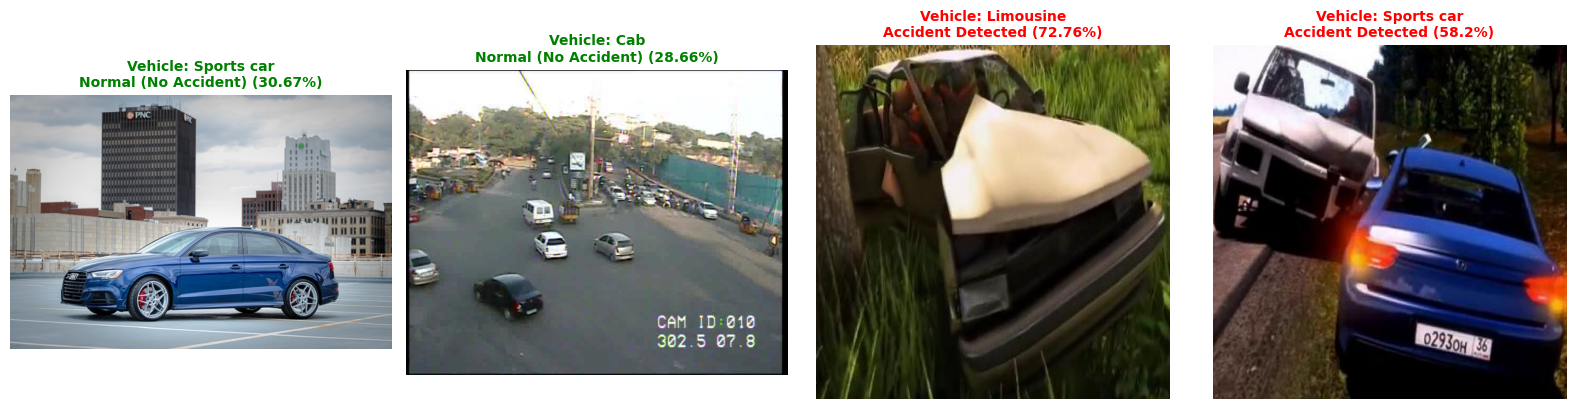

In [5]:
test_dir = 'Sample_Test_Images'
if os.path.exists(test_dir):
    sample_images = [os.path.join(test_dir, f) for f in os.listdir(test_dir) if f.endswith(('.jpg', '.png'))][:4]
    
    plt.figure(figsize=(16, 4))
    for idx, p in enumerate(sample_images):
        res = predict_accident_pipeline(p)
        img = Image.open(p)
        
        plt.subplot(1, len(sample_images), idx + 1)
        plt.imshow(img)
        plt.axis('off')
        
        title_color = 'red' if res['status'] == 'Alert' else 'green'
        veh_text = f"Vehicle: {res.get('vehicle_type')}" if res['vehicle_detected'] else "No Vehicle"
        plt.title(f"{veh_text}\n{res['prediction']} ({res.get('accident_confidence', 0)}%)", color=title_color, fontsize=10, fontweight='bold')
        
    plt.tight_layout()
    plt.show()
else:
    print('Sample_Test_Images directory not found.')
